# Segmentação de uma pluma de fumaça com SAM 2

**Grupo:** André Ferreira Santos (176013), André Souza de Almeida (176024), Letícia Abrahão Moreira (176559), Lucas Alves Gazale (176565)

**Caso:** incêndio na Refinaria Henrique Lage (Revap), São José dos Campos (SP), 29/09/2019, parte do projeto da disciplina de Modelagem Computacional.

**Objetivo:** segmentar a pluma de fumaça em uma fotografia com o SAM 2.1, comparar diferentes prompts (caixa, pontos positivos e negativos), avaliar os erros da máscara e discutir o que dificultou a segmentação.

**Como o notebook está organizado:** carregamento do modelo e da imagem → seis configurações de prompt → tabela comparativa → pós-processamento → análise de iluminação, contraste e semelhança com nuvem → análise dos resultados.


In [19]:
!pip install -q -U transformers accelerate

In [20]:
import numpy as np, pandas as pd, cv2, torch
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
from transformers import Sam2Processor, Sam2Model

device = "cuda" if torch.cuda.is_available() else "cpu"
model_id = "facebook/sam2.1-hiera-small"
processor = Sam2Processor.from_pretrained(model_id)
model = Sam2Model.from_pretrained(model_id).to(device).eval()
print("Rodando em:", device)

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/357 [00:00<?, ?it/s]

Rodando em: cuda


Largura x altura: 984 x 738


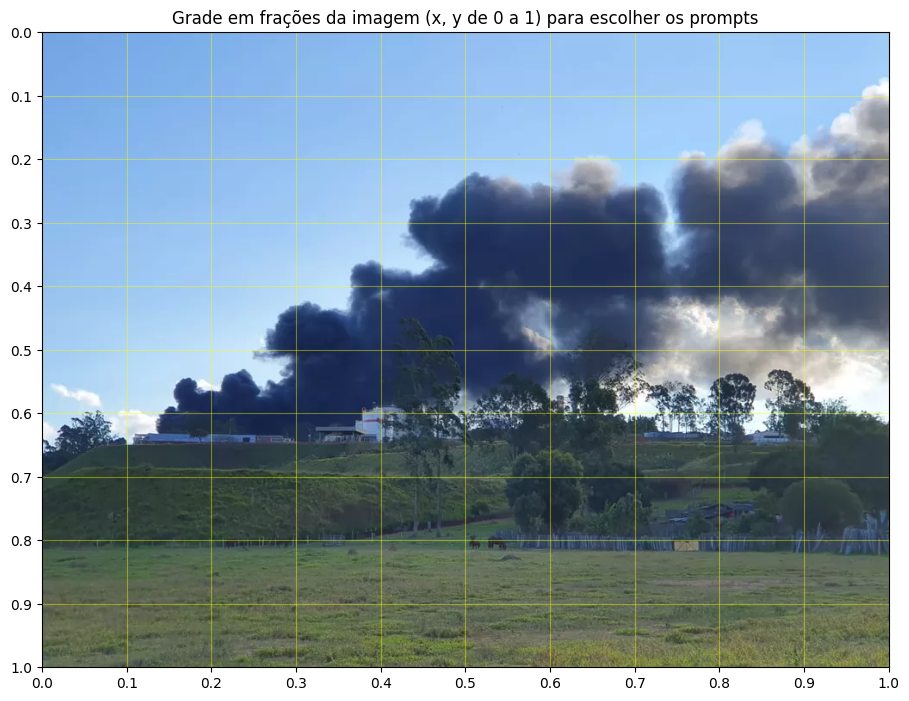

In [21]:
IMAGEM = "/content/plumaa.jpg"
MAX_LADO = 1600                # reduz imagens grandes (as coordenadas são frações, então não atrapalha)

image = Image.open(IMAGEM).convert("RGB")
if max(image.size) > MAX_LADO:
    esc = MAX_LADO / max(image.size)
    image = image.resize((int(image.width * esc), int(image.height * esc)), Image.LANCZOS)
img_np = np.array(image)
H, W = img_np.shape[:2]
print("Largura x altura:", W, "x", H)

fig, ax = plt.subplots(figsize=(11, 11 * H / W))
ax.imshow(img_np)
ax.set_xticks(np.linspace(0, W, 11)); ax.set_xticklabels([f"{f:.1f}" for f in np.linspace(0, 1, 11)])
ax.set_yticks(np.linspace(0, H, 11)); ax.set_yticklabels([f"{f:.1f}" for f in np.linspace(0, 1, 11)])
ax.grid(color="yellow", alpha=0.4)
ax.set_title("Grade em frações da imagem (x, y de 0 a 1) para escolher os prompts")
plt.show()

In [22]:
def px(p):               # fração (x, y) -> pixel
    return [p[0] * W, p[1] * H]

def segmentar(caixa=None, pos=(), neg=(), multimask=True, img=None):
    """caixa em frações (x1,y1,x2,y2); pos/neg: listas de (x,y) em frações."""
    kw = {}
    pts = [px(p) for p in list(pos) + list(neg)]
    if pts:
        kw["input_points"] = [[pts]]
        kw["input_labels"] = [[[1] * len(pos) + [0] * len(neg)]]
    if caixa is not None:
        kw["input_boxes"] = [[[caixa[0]*W, caixa[1]*H, caixa[2]*W, caixa[3]*H]]]
    inputs = processor(images=image if img is None else img, return_tensors="pt", **kw).to(device)
    with torch.no_grad():
        out = model(**inputs, multimask_output=multimask)
    masks = processor.post_process_masks(out.pred_masks.cpu(), inputs["original_sizes"])[0][0].numpy() > 0
    scores = out.iou_scores.cpu().numpy().flatten()
    i = int(scores.argmax())
    return masks[i], float(scores[i])

def iou(a, b):
    u = np.logical_or(a, b).sum()
    return float(np.logical_and(a, b).sum() / u) if u else np.nan

def mostrar(mask, titulo, caixa=None, pos=(), neg=()):
    fig, ax = plt.subplots(1, 3, figsize=(18, 5))
    ax[0].imshow(img_np); ax[0].set_title("Imagem original")
    ax[1].imshow(mask, cmap="gray"); ax[1].set_title("Máscara binária")
    ov = img_np.copy()
    ov[mask] = (0.5 * ov[mask] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
    ax[2].imshow(ov); ax[2].set_title("Máscara sobreposta")
    for p in pos: ax[2].scatter(*px(p), c="lime", marker="*", s=200, edgecolors="k")
    for p in neg: ax[2].scatter(*px(p), c="red", marker="*", s=200, edgecolors="k")
    if caixa is not None:
        x1, y1, x2, y2 = caixa[0]*W, caixa[1]*H, caixa[2]*W, caixa[3]*H
        ax[2].plot([x1, x2, x2, x1, x1], [y1, y1, y2, y2, y1], "y-", lw=2)
    for a in ax: a.axis("off")
    fig.suptitle(titulo); plt.tight_layout(); plt.show()

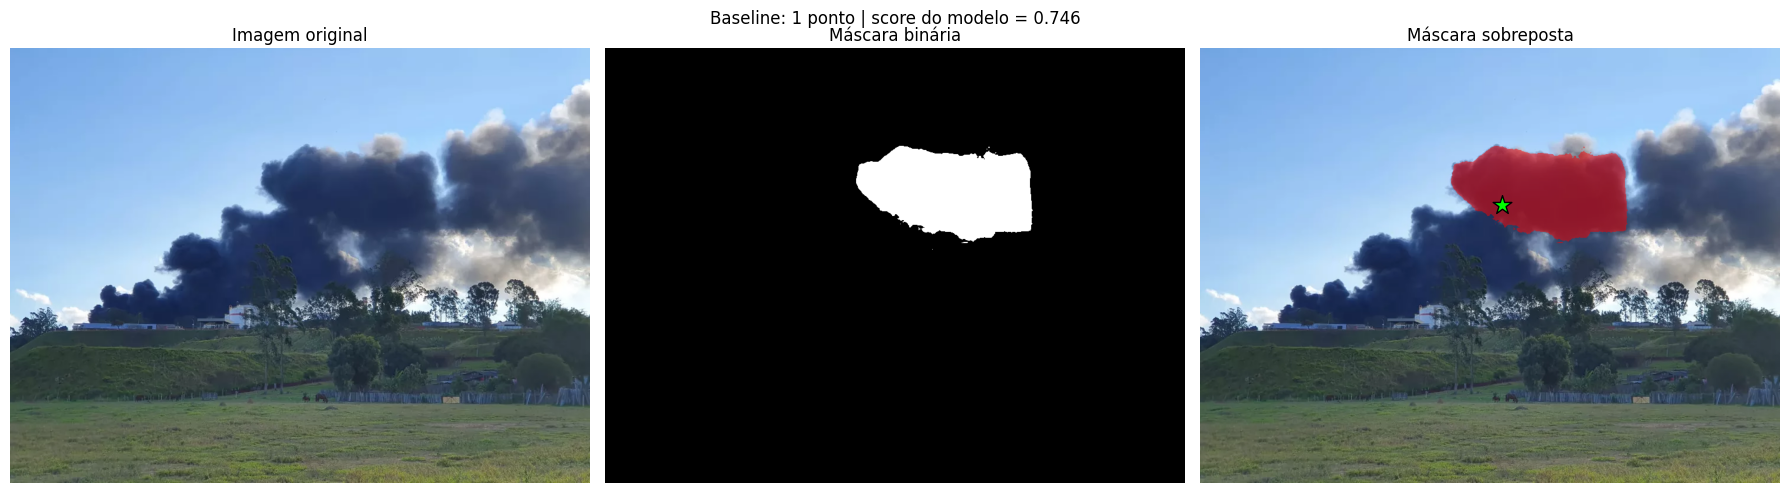

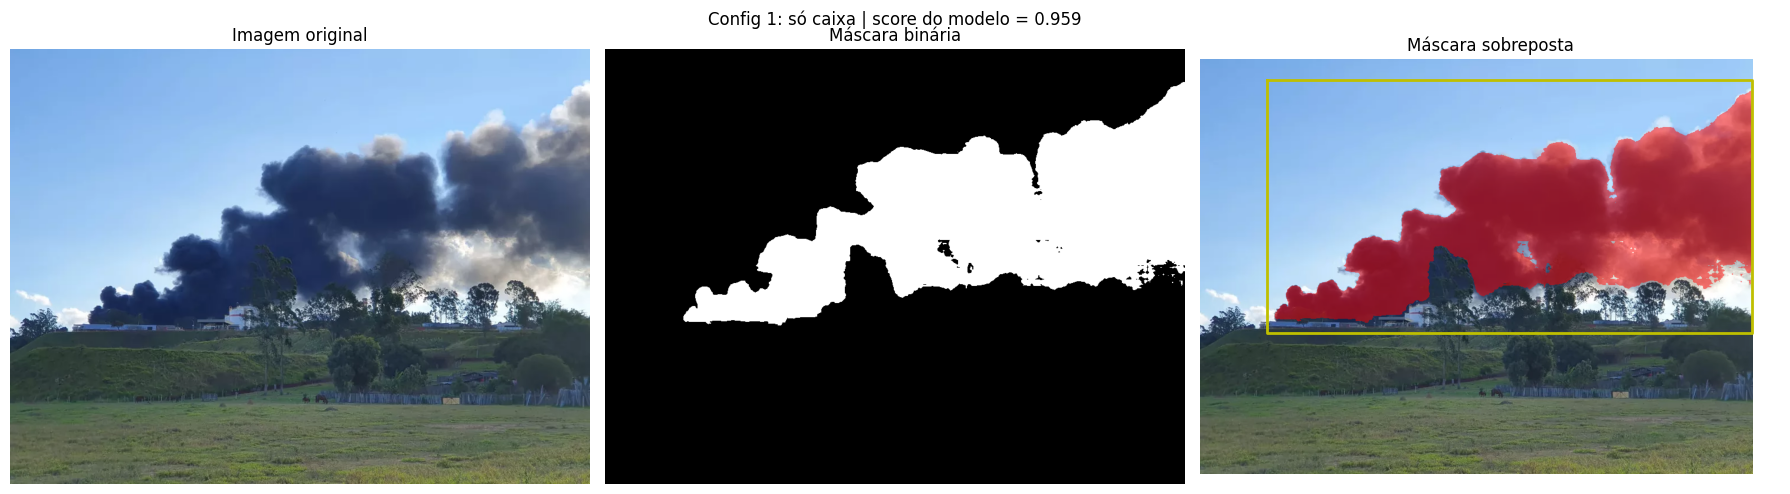

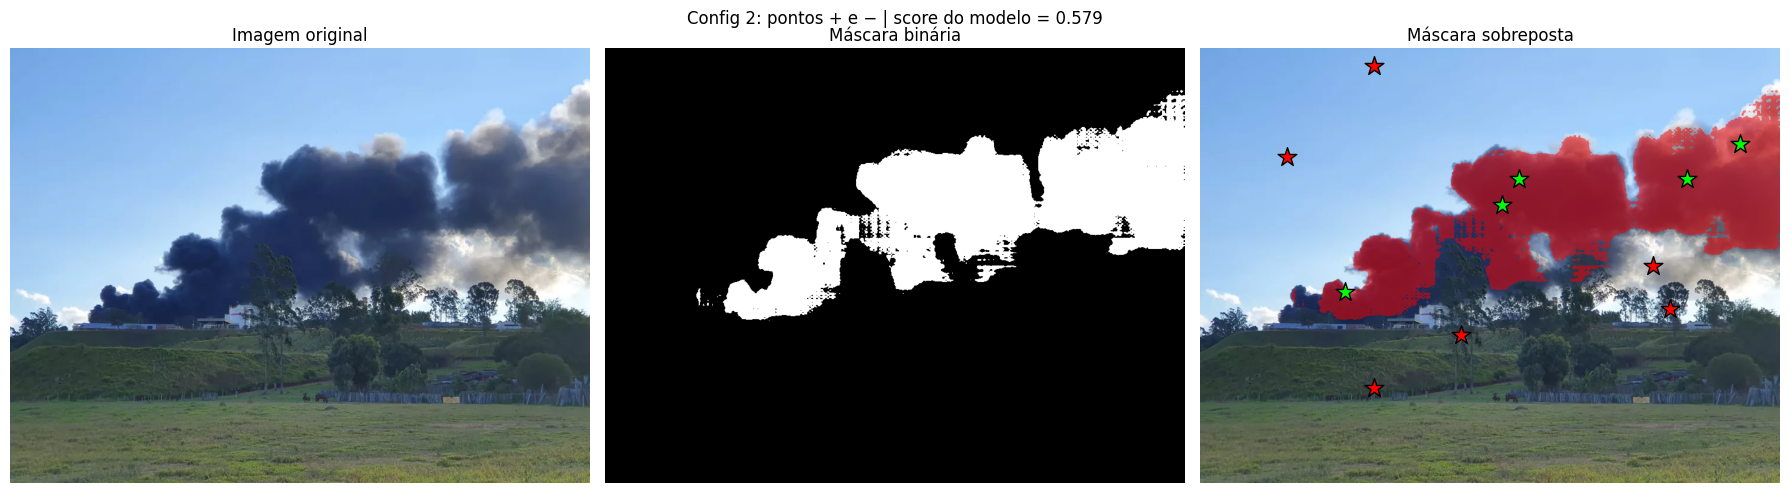

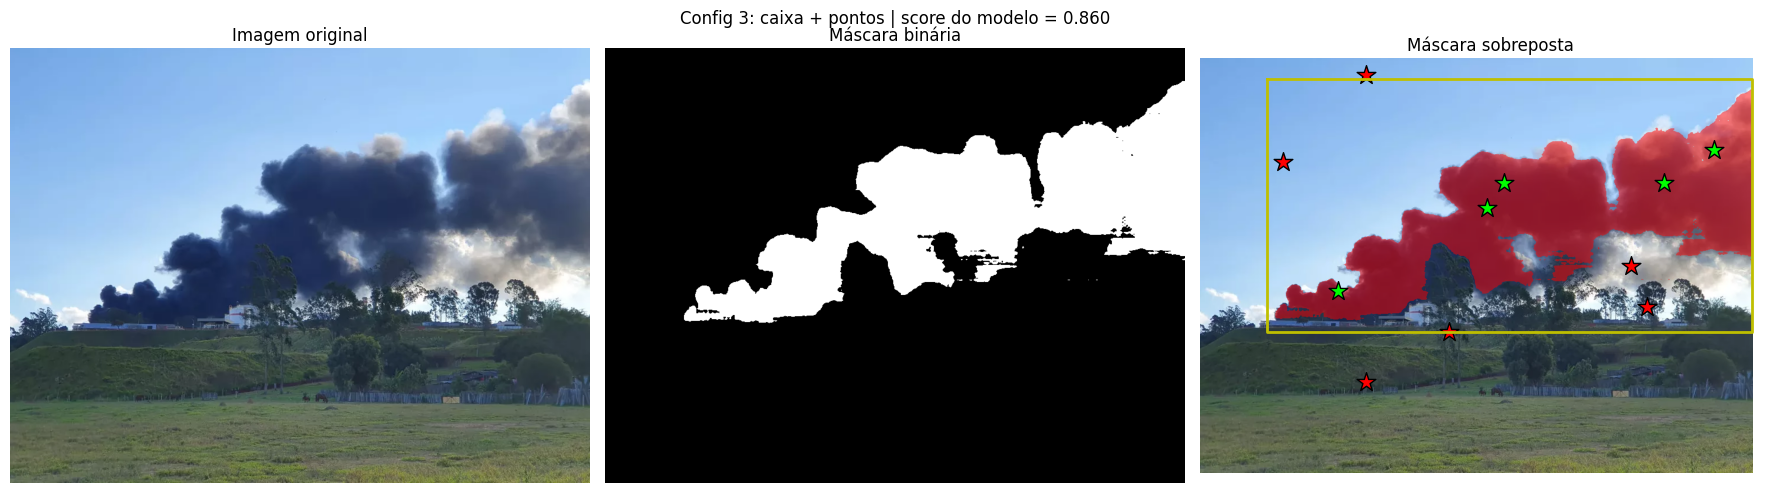

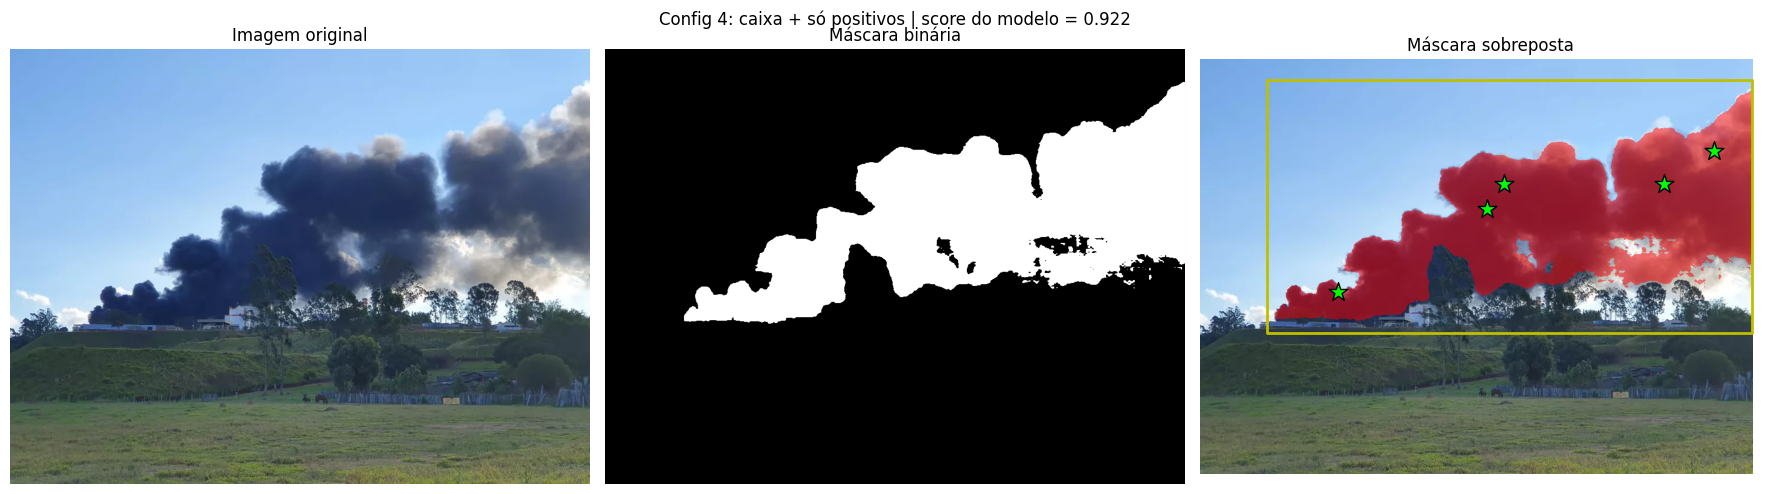

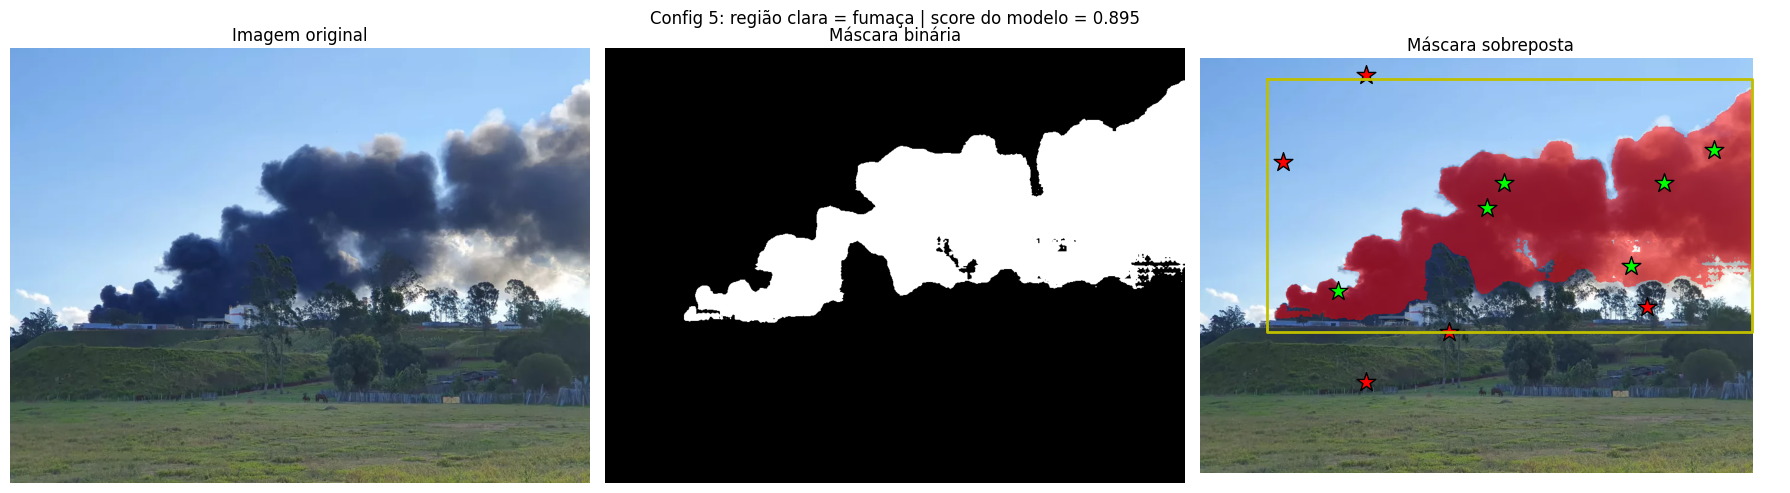

In [23]:
caixa = (0.12, 0.05, 1.0, 0.66)

pos = [(0.52, 0.36),   # núcleo escuro da massa central
       (0.25, 0.56),   # base à esquerda
       (0.84, 0.30),   # massa escura à direita
       (0.55, 0.30),   # parte superior da massa central
       (0.93, 0.22)]   # fumaça cinza no alto à direita

AMBIGUO = (0.78, 0.50)  # brilho claro à direita: nuvem ou fumaça iluminada?

neg = [(0.15, 0.25),   # céu azul à esquerda
       (0.30, 0.04),   # céu azul no topo
       (0.45, 0.66),   # árvore na frente da base
       (0.81, 0.60),   # árvores à direita
       (0.30, 0.78),   # morro/pasto
       AMBIGUO]        # tratado como nuvem (fora da pluma)

configs = {
    "Baseline: 1 ponto":              dict(pos=[pos[0]]),
    "Config 1: só caixa":             dict(caixa=caixa),
    "Config 2: pontos + e −":         dict(pos=pos, neg=neg),
    "Config 3: caixa + pontos":       dict(caixa=caixa, pos=pos, neg=neg),
    "Config 4: caixa + só positivos": dict(caixa=caixa, pos=pos),
    "Config 5: região clara = fumaça": dict(caixa=caixa, pos=pos + [AMBIGUO],
                                            neg=[p for p in neg if p != AMBIGUO]),
}

mascaras, scores = {}, {}
for nome, cfg in configs.items():
    m, s = segmentar(**cfg)
    mascaras[nome], scores[nome] = m, s
    mostrar(m, f"{nome} | score do modelo = {s:.3f}", **cfg)

In [24]:
# regiões SEM fumaça (frações x1,y1,x2,y2) onde o SAM tende a errar
proibidas = {"nuvem clara (dir.)": (0.72, 0.47, 0.90, 0.57),
             "copas das árvores": (0.40, 0.56, 0.62, 0.66),
             "céu": (0.02, 0.05, 0.25, 0.22)}

def frac_em(mask, r):
    x1, y1, x2, y2 = int(r[0]*W), int(r[1]*H), int(r[2]*W), int(r[3]*H)
    return 100 * mask[y1:y2, x1:x2].sum() / max(mask.sum(), 1)

ref = mascaras["Config 3: caixa + pontos"]
linhas = []
for n, m in mascaras.items():
    l = {"config": n, "área (% imagem)": round(100 * m.mean(), 1),
         "score do modelo": round(scores[n], 3), "IoU vs Config 3": round(iou(m, ref), 3)}
    for rn, r in proibidas.items():
        l[f"% da máscara em {rn}"] = round(frac_em(m, r), 2)
    linhas.append(l)
tabela = pd.DataFrame(linhas).set_index("config")
display(tabela)

,área (% imagem),score do modelo,IoU vs Config 3,% da máscara em nuvem clara (dir.),% da máscara em copas das árvores,% da máscara em céu
config,,,,,,
Baseline: 1 ponto,4.9,0.746,0.265,0.00,0.00,0.0
Config 1: só caixa,22.3,0.959,0.831,5.70,0.24,0.0
Config 2: pontos + e −,16.8,0.579,0.898,0.10,0.00,0.0
Config 3: caixa + pontos,18.5,0.860,1.000,0.15,0.19,0.0
Config 4: caixa + só positivos,21.3,0.922,0.870,4.99,0.26,0.0
Config 5: região clara = fumaça,21.7,0.895,0.852,5.77,0.19,0.0


Área antes: 134570 px | depois: 132729 px | IoU antes/depois: 0.985


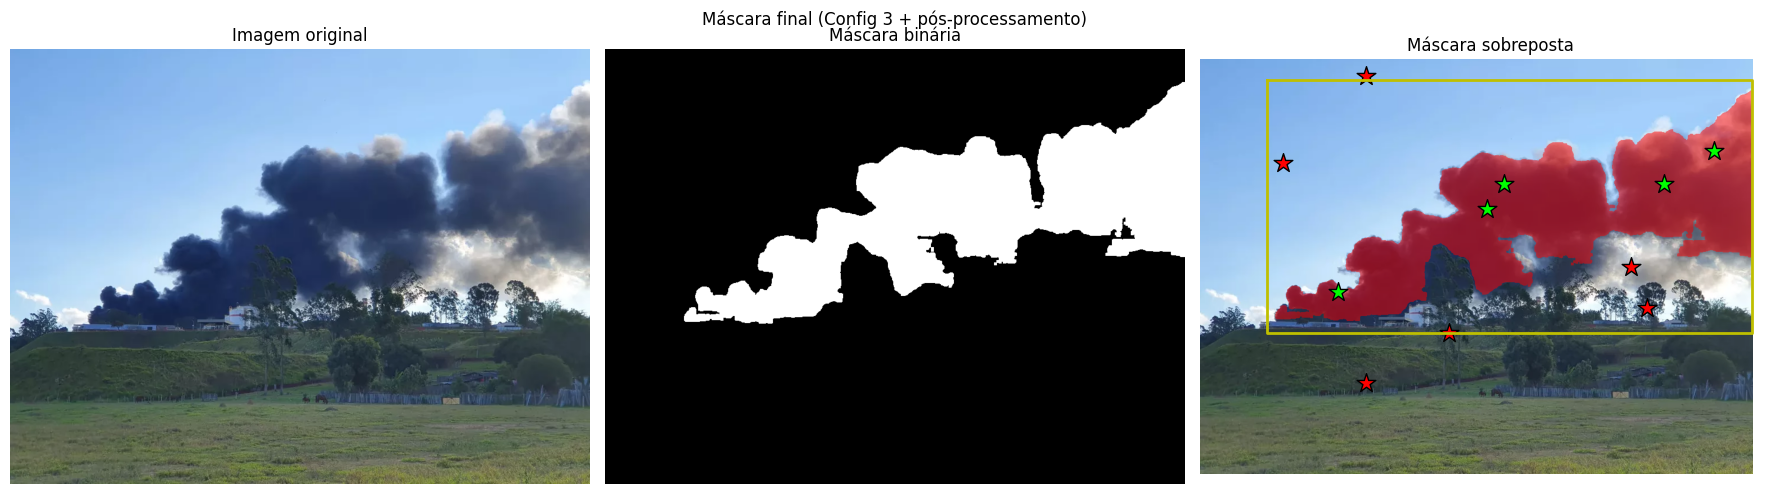

In [25]:
def limpar(mask, abertura=5):
    m = ndi.binary_opening(mask, structure=np.ones((abertura, abertura)))   # tira ruído fino
    lab, n = ndi.label(m)
    if n > 1:                                                               # fica só com o maior pedaço
        tam = ndi.sum(m, lab, range(1, n + 1))
        m = lab == (1 + int(np.argmax(tam)))
    return ndi.binary_fill_holes(m)                                         # fecha buracos internos

final = limpar(mascaras["Config 3: caixa + pontos"])
print(f"Área antes: {ref.sum()} px | depois: {final.sum()} px | IoU antes/depois: {iou(ref, final):.3f}")
mostrar(final, "Máscara final (Config 3 + pós-processamento)", caixa=caixa, pos=pos, neg=neg)

Image.fromarray((final * 255).astype(np.uint8)).save("mascara_final.png")

In [26]:
lab_cv = cv2.cvtColor(img_np, cv2.COLOR_RGB2LAB).astype(np.float32)
L = lab_cv[..., 0] * 100 / 255
LAB = np.stack([L, lab_cv[..., 1] - 128, lab_cv[..., 2] - 128], axis=-1)

def caixa_mask(r):
    m = np.zeros((H, W), bool); m[int(r[1]*H):int(r[3]*H), int(r[0]*W):int(r[2]*W)] = True; return m

k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (61, 61))
anel = cv2.dilate(final.astype(np.uint8), k).astype(bool) & ~final      # faixa em volta da pluma
ref_ceu = caixa_mask((0.02, 0.05, 0.25, 0.22))
ref_nuvem = caixa_mask((0.72, 0.47, 0.90, 0.57))   # mesma região "nuvem clara" da tabela

cor = lambda m: LAB[m].mean(axis=0)
dE = lambda a, b: float(np.linalg.norm(cor(a) - cor(b)))

print("Brilho médio (L*) | imagem:", round(L.mean(), 1), "| pluma:", round(L[final].mean(), 1),
      "| anel:", round(L[anel].mean(), 1))
print("Desvio-padrão do brilho dentro da pluma:", round(L[final].std(), 1), "(alto = iluminação irregular)")
print("ΔE pluma × anel (contraste com o entorno):", round(dE(final, anel), 1))
print("ΔE pluma × céu:", round(dE(final, ref_ceu), 1))
print("ΔE pluma × nuvem:", round(dE(final, ref_nuvem), 1), "(quanto menor, mais parecida)")

Brilho médio (L*) | imagem: 51.8 | pluma: 33.5 | anel: 63.2
Desvio-padrão do brilho dentro da pluma: 16.2 (alto = iluminação irregular)
ΔE pluma × anel (contraste com o entorno): 30.8
ΔE pluma × céu: 40.7
ΔE pluma × nuvem: 38.5 (quanto menor, mais parecida)


## Análise dos resultados

**Imagem:** incêndio na Revap (29/09/2019), 984 × 738 px, segmentada com SAM 2.1.

### 1. Avaliação das máscaras

- **Baseline (1 ponto):** cobriu só 4,9% da imagem, um trecho da massa central. A base e a massa da direita ficaram de fora.
- **Só caixa:** cobriu as três massas (22,3%) e teve o maior score (0,959), mas 5,7% da máscara está sobre a nuvem clara à direita, região que provavelmente não é fumaça.
- **Só pontos + e −:** menor score (0,579) e máscara fragmentada. Os negativos evitaram a nuvem (0,10%), mas sem a caixa a pluma foi subestimada.
- **Caixa + pontos + e − (Config 3):** melhor equilíbrio. Cobre núcleo, base e cinza do topo (18,5%, score 0,860) e só 0,15% da máscara cai na nuvem clara.
- **Região clara como fumaça (Config 5):** a área subiu para 21,7%, mostrando que essa decisão ambígua altera o resultado.

O score mede a confiança do modelo, não a qualidade: a Config 1 tem o maior score e mais erro que a Config 3.

### 2. O que dificultou

- **Iluminação:** brilho médio da pluma 33,5, contra 63,2 no entorno; desvio-padrão 16,2. O topo e as bordas cinza claro, iluminados pelo sol, foram as áreas mais difíceis.
- **Contraste:** ΔE pluma × entorno = 30,8, alto, o que favoreceu o núcleo escuro. As bordas translúcidas têm menos contraste.
- **Semelhança com nuvem:** ΔE pluma × nuvem = 38,5 e pluma × céu = 40,7. A cor média quase não diferencia os dois; a confusão vem da região onde fumaça e nuvem se misturam. As árvores à frente também interromperam a máscara.

### 3. Melhorias

Seis configurações de prompt (uma variação por vez), coordenadas relativas à imagem, tabela com área, score, IoU e % da máscara em regiões sem fumaça, figuras lado a lado e pós-processamento (IoU antes/depois de 0,985, ou seja, a máscara já estava limpa).

### 4. Limitações

Sem máscara de referência, a avaliação é visual e indireta. A região clara é ambígua (decisão minha), e as regiões da tabela foram escolhidas à mão.
